# Importing Libraries


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


Dataset Link: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset


# Test set Image Processing


In [2]:
test_set = tf.keras.utils.image_dataset_from_directory(
    "dataset/valid",
    labels="inferred",
    label_mode="categorical",
    image_size=(128, 128),
    batch_size=32,
    shuffle=False,
)


Found 17572 files belonging to 38 classes.


# Loading Model


In [3]:
cnn = tf.keras.models.load_model("trained_plant_disease_model.keras")
cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,988 (1.31 MB)

 Trainable params: 114,662 (447.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 229,326 (895.81 KB)

In [4]:
import tensorflow as tf
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


Available GPUs: []


# Visualising and Performing Prediction on Single image


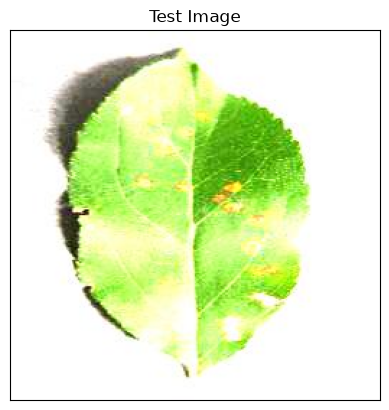

In [5]:
# Test Image Visualization
import cv2
import matplotlib.pyplot as plt

image_path = "test/test/AppleCedarRust1.JPG"
# Reading an image in default mode
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Converting BGR to RGB

# Displaying the image
plt.imshow(img)
plt.title("Test Image")
plt.xticks([])
plt.yticks([])
plt.show()


## Testing Model


In [6]:
# Load image with bilinear interpolation to preserve fine disease textures
image = tf.keras.preprocessing.image.load_img(
    image_path,
    target_size=(128, 128),
    interpolation="bilinear"
)
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.array([input_arr])  # Convert single image to a batch.
predictions = cnn.predict(input_arr)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step


In [7]:
print("Predictions shape:", predictions.shape)
print(predictions)


Predictions shape: (1, 38)
[[1.0748686e-05 8.6354999e-07 6.2112218e-01 5.1385647e-05 3.2205779e-02
  2.2950761e-04 2.8274856e-06 3.9961797e-08 9.0378416e-09 9.1012496e-11
  2.3294633e-07 5.6552707e-04 1.3669941e-05 8.8781981e-06 3.1985726e-02
  5.6497443e-06 1.1996112e-04 1.4224244e-06 2.1864772e-03 2.5483248e-01
  4.0004795e-07 1.1893854e-07 1.6671917e-03 4.6389490e-02 1.0522658e-07
  3.7630122e-07 4.1389463e-05 1.1535590e-06 3.3393405e-08 7.5347784e-06
  7.5455406e-03 1.2866770e-06 2.6464774e-04 8.5887869e-10 6.2772966e-07
  7.3560636e-04 5.8432686e-08 1.0065762e-06]]


In [8]:
result_index = np.argmax(predictions) # Return index of max element
print("Predicted Class Index:", result_index)


Predicted Class Index: 2


In [9]:
class_name = test_set.class_names
print("Total classes:", len(class_name))


Total classes: 38


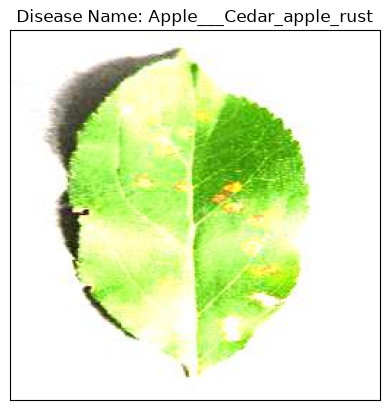

Prediction: Apple___Cedar_apple_rust (62.11% confidence)


In [10]:
# Displaying the disease prediction
model_prediction = class_name[result_index]
confidence = predictions[0][result_index] * 100
plt.imshow(img)
plt.title(f"Disease Name: {model_prediction}")
plt.xticks([])
plt.yticks([])
plt.show()
print(f"Prediction: {model_prediction} ({confidence:.2f}% confidence)")
